In [1]:
#!pip install numpy
#!pip install sklearn

In [1]:
import numpy as np
import sklearn as skl

In [3]:
from IPython.core.display import HTML
HTML("""
<style>
.consignes{
  font-weight: bold;
  color: #3256a8;
  background-color: #edebdf
}
</style>
""")



# TP2: Détection de menaces radar

<div class=consignes> Listez les noms des étudiants (2 au maximum) ayant participé à ce notebook dans la cellule suivante (prénom, nom, affectation).<br/>
Au moment du rendu, le notebook doit être nommé nom1_nom2_dlts_tp2.ipynb 

Deadline pour le rendu : 04 novembre 2026, 13h59, par mail à deepetsignal.mva@gmail.com <br> 

Pour installer les paquets nécessaires à la réalisation de ce TP vous pouvez utiliser dans le notebook 
    
```
!pip install \< nom_du_paquet \>
```
merci de regrouper toutes les installations dans la première cellule du notebook. 
Essayez de faire en sorte que votre notebook puisse se lire comme un compte rendu, évitez de laisser du code mort et prennez le temps de commenter vos observations et résultats.

    
## Mission


Vous commandez un avion de reconnaissance en mission top secrète. Malgré votre discretion et toutes les précautions prises vous dérangez et pouvez être sujet de menaces qu'il vous faut détecter pour garantir la sécurité de votre équipage et la succès de votre mission (comme elle est top secrète vous ne pouvez pas en savoir plus). 

A votre disposition un réseau d'antennes et un système d'analyse spectrale perfectionnés vous permettent d'extraire et de caractériser des signaux en provenance des radars à altitude 0 qui parsèment votre parcours. 

Un signal radar est composé d'impulsions. Le système d'analyse vous permettent de caractériser chaque impulsion reçue par une structure de données dite PDW (Pulse Description Word) assimilable à un dictionnaire qui contient: 

- la date de début de détection de l'impulsion (en ms)
- la largeur ou durée de l'impulsion (en ms)
- la puissance de l'impulsion (en dB / référence) 
- l'angle theta et l'angle phi décrivant la direction dans laquelle l'impulsion est détectée (en radians)
- la fréquence de l'impulsion (en Ghz)

Votre capteur n'est pas parfait, les différentes quantitées mesurées sont bruitées, les impulsions dont la puissance est inférieure à -100 dB ne sont pas mesurées  et vous subissez un phénomène de mitage: une certaine proportion des impulsions émises ne sont pas détectées (jusqu'à 90 pourcents voire un peu plus).  

Votre avion navigue à 10 km d'altitude, avec une vitesse constante de 1000 km/h vers le nord. 

De précédentes missions ont permis de réaliser une base de données de signaux de différentes durées de l'ordre de 15 à 20 secondes. 
Chaque signal se présente sous la forme d'un fichier .npz qui contient l'ensemble des PDW reçus. 

Un signal est donc un fichier dont le nom est de la forme 'pdw_<numéro du signal>.npz'.

Cette base de données est annotée: le destin de chaque mission a permis de déclarer chaque signal comme une 'menace' ou une 'nonmenace'. 

Les signaux ont été divisés en trois ensembles indépendants: 
    
- train
- valid
- test 
 
Les annotations pour chaque ensemble sont disponibles dans le fichier labels_<train ou valid ou test>.json qui donne l'association nom de fichier -> menace ou nonmenace. 
    
    
Votre mission (si vous l'acceptez) est de choisir et d'entrainer un algorithme d'apprentissage machine à détecter les menaces sur l'ensemble 'train' et à évaluer ses performances sur l'ensemble 'test'. 

Fort de votre expérience passée, vous décidez de suivre la méthodologie suivante: 

- Visualisation et analyse des données pour trouver les paramètres les plus pertinents à utiliser 
- Sélection d'un algorithme naïf "baseline" de référence: pour vous lancer et faire une évaluation de la difficulté du problème, vous définissez un premier algorithme simple (simple = moins de 20 lignes de code et/ou moins de 20 minutes de réflexion) et caractérisez ses performances qui serviront de point de comparaison pour qualifier l'apport d'algorithmes plus sophistiqués 
- Vous utilisez la bibliothèque sklearn et notamment ses implémentations d'algorithmes de classification binaire pour définir et entrainer sur l'ensemble 'train' un ou plusieurs algorithmes en capacité de prédire le label menance ou nonmenace de chaque signal (https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html)
- Vous qualifiez les performances de vos algorithmes en termes d'accuracy (https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html#sklearn.metrics.accuracy_score) ; vous calculez aussi les matrices de confusion (https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html#sklearn.metrics.confusion_matrix)
    
Pour ce TP nous ne cherchons pas à mettre en place des algorithmes d'apprentissage profond. Ces méthodes pourront être investiguées dans un deuxième temps.
    
 Si les résultats vous semblent décevants, souvenez vous des conseils de votre prédecesseur et mentor G. Abitbol: "toujours donner un coup de pouce à un algo de machine learning  en lui présentant les bonnes données"

Vous pouvez ouvrir un fichier de la façon suivante:

</div>    

In [40]:
pdws = np.load('./donnees/train/pdw-0.npz')
dates = np.asarray(pdws['date'], dtype=np.float64)
largeurs = pdws['largeur']
frequences=pdws['frequence']
puissances = pdws['puissance']
theta = pdws['theta']
phi = pdws['phi']


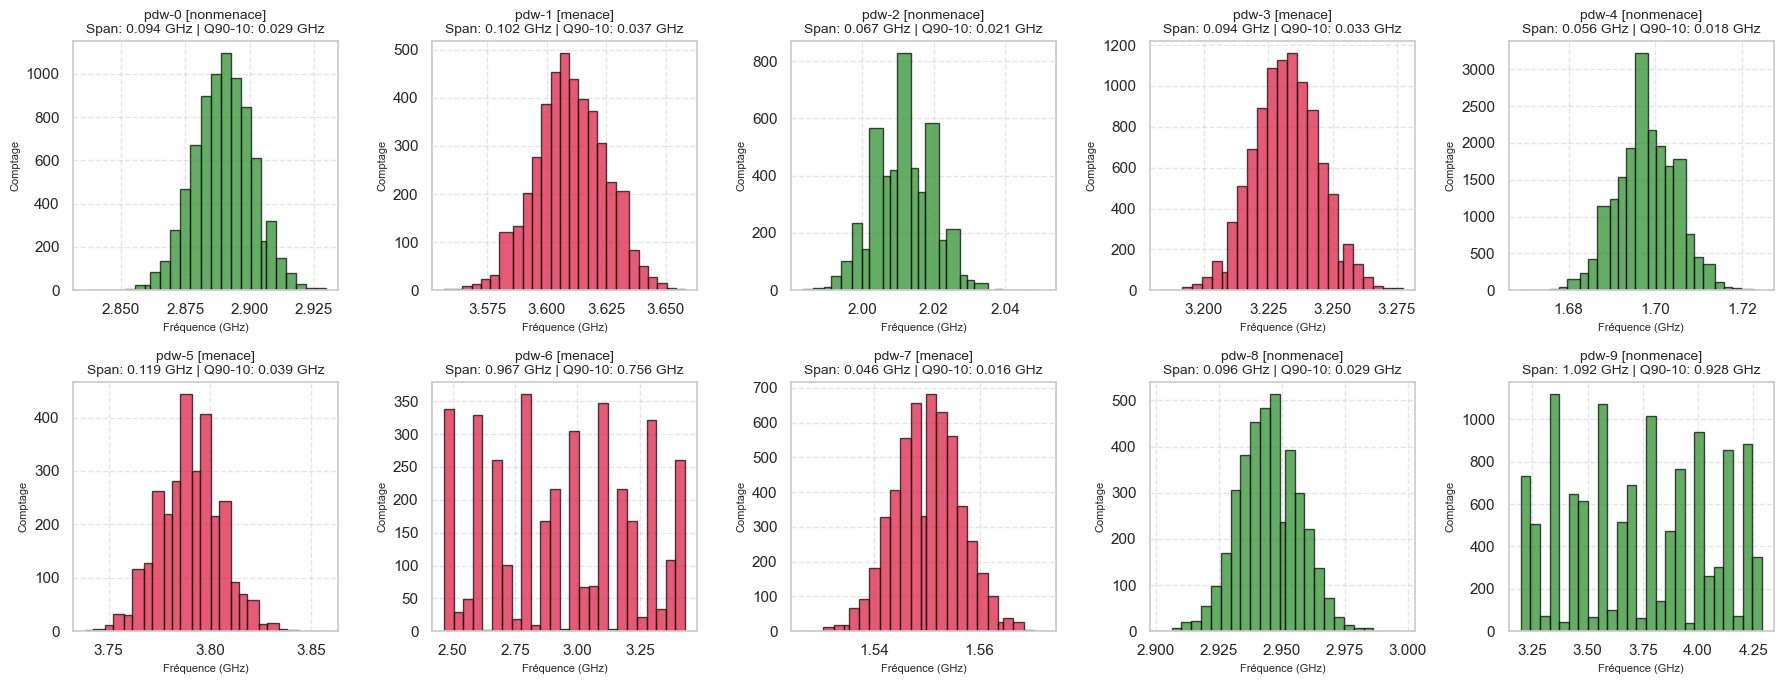

In [48]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Charger les labels
labels_path = Path('./donnees/train_labels.json')
dict_labels = {}
if labels_path.exists():
  with open(labels_path) as f:
    dict_labels = json.load(f)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

for i in range(10):
  path = f'./donnees/train/pdw-{i}.npz'
  pdws = np.load(path)
  frequences = pdws['frequence']

  # Métriques d'étalement
  span = np.ptp(frequences)  # max(f) - min(f)
  q10, q90 = np.percentile(frequences, [10, 90])
  q_span = q90 - q10  # Étalement à 80% (robuste au bruit)
  std_f = np.std(frequences)

  # Label et couleur
  label = dict_labels.get(f'pdw-{i}', '')
  title_label = f' [{label}]' if label else ''
  color = (
      'crimson'
      if label == 'menace'
      else ('forestgreen' if label == 'nonmenace' else 'steelblue')
  )

  ax = axes[i]
  ax.hist(frequences, bins=25, color=color, edgecolor='black', alpha=0.7)
  ax.set_title(
      f'pdw-{i}{title_label}\nSpan: {span:.3f} GHz | Q90-10: {q_span:.3f} GHz',
      fontsize=10,
  )
  ax.set_xlabel('Fréquence (GHz)', fontsize=8)
  ax.set_ylabel('Comptage', fontsize=8)
  ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

<div class=consignes> et les fichiers d'annotations:</div>

In [3]:
import json

with open('./donnees/train_labels.json') as f: 
    dict_labels = json.load(f)

for i in range(10):
    print(f"Le signal pdw-{i}.npz est de type: {dict_labels[f'pdw-{i}']}")

Le signal pdw-0.npz est de type: nonmenace
Le signal pdw-1.npz est de type: menace
Le signal pdw-2.npz est de type: nonmenace
Le signal pdw-3.npz est de type: menace
Le signal pdw-4.npz est de type: nonmenace
Le signal pdw-5.npz est de type: menace
Le signal pdw-6.npz est de type: menace
Le signal pdw-7.npz est de type: menace
Le signal pdw-8.npz est de type: nonmenace
Le signal pdw-9.npz est de type: nonmenace


<div class=consignes> On compte sur vous, bonne chance ! </div>

In [50]:
from pathlib import Path
import json
import numpy as np
from scipy.stats import kurtosis, skew

def extract_features_from_pdw(pdw):
    # 1. Chargement et tri des dates
    dates = np.sort(np.asarray(pdw['date'], dtype=np.float64))
    
    largeurs = np.asarray(pdw['largeur'], dtype=np.float64)
    frequences = np.asarray(pdw['frequence'], dtype=np.float64)
    puissances = np.asarray(pdw['puissance'], dtype=np.float64)
    theta = np.asarray(pdw['theta'], dtype=np.float64)
    phi = np.asarray(pdw['phi'], dtype=np.float64)
    
    # 2. Calcul du PRI sur dates triées (filtrage des gaps > 50 ms pour isoler le vrai PRI)
    if len(dates) > 1:
        raw_pri = np.diff(dates)
        valid_pri = raw_pri[(raw_pri > 0.0) & (raw_pri < 50.0)]
        pri = valid_pri if len(valid_pri) > 0 else np.array([0.0], dtype=np.float64)
    else:
        pri = np.array([0.0], dtype=np.float64)
    
    # 3. Features statistiques standard (Moyenne, std, min, max, médiane)
    features = []
    variables = [frequences, largeurs, puissances, theta, phi, pri]
    
    for var in variables:
        if len(var) == 0:
            features.extend([0.0, 0.0, 0.0, 0.0, 0.0])
        else:
            features.extend([
                np.mean(var),
                np.std(var),
                np.min(var),
                np.max(var),
                np.median(var)
            ])
            
    # 4. Features spécifiques à la forme de la distribution de fréquence
    if len(frequences) > 3:
        freq_span = float(np.ptp(frequences)) # max - min
        q10, q25, q75, q90 = np.percentile(frequences, [10, 25, 75, 90])
        freq_q90_10 = float(q90 - q10)        # Étalement à 80%
        freq_iqr = float(q75 - q25)           # Écart interquartile
        
        # Entropie spectrale sur 20 bins
        counts, _ = np.histogram(frequences, bins=20)
        probs = counts / len(frequences)
        probs = probs[probs > 0]
        freq_entropy = float(-np.sum(probs * np.log2(probs)))
        
        # Flag binaire : 1 si peigne/agile (> 0.4 GHz), 0 si mono-fréquence
        is_agile_freq = 1.0 if freq_q90_10 > 0.4 else 0.0
    else:
        freq_span = 0.0
        freq_q90_10 = 0.0
        freq_iqr = 0.0
        freq_entropy = 0.0
        is_agile_freq = 0.0

    features.extend([freq_span, freq_q90_10, freq_iqr, freq_entropy, is_agile_freq])
    
    # 5. Nombre total d'impulsions
    features.append(float(len(dates)))
    
    return np.array(features, dtype=np.float64)

def load_dataset(data_dir, labels_json_path):
    with open(labels_json_path, 'r') as f:
        labels_dict = json.load(f)
        
    X, y = [], []
    data_path = Path(data_dir)
    
    for fname, label in labels_dict.items():
        filepath = data_path / f"{fname}.npz"
        if not filepath.exists():
            continue
            
        pdw = np.load(filepath)
        feat = extract_features_from_pdw(pdw)
        
        X.append(feat)
        y.append(1 if label == 'menace' else 0)
        
    return np.array(X), np.array(y)

In [51]:
X_train, y_train = load_dataset('./donnees/train', './donnees/train_labels.json')
X_valid, y_valid = load_dataset('./donnees/valid', './donnees/valid_labels.json')
X_test, y_test = load_dataset('./donnees/test', './donnees/test_labels.json')

print(f"Forme de X_train : {X_train.shape}")
print(f"Forme de y_train : {y_train.shape}")

Forme de X_train : (2000, 36)
Forme de y_train : (2000,)


In [12]:
print(X_train[0,:])

[ 2.88894216e+00  1.14614043e-02  2.83593750e+00  2.92968750e+00
  2.88867188e+00  1.28100733e-01  6.01892040e-03  1.17980957e-01
  1.37939453e-01  1.28051758e-01 -8.68545437e+01  8.21714348e+00
 -1.00000000e+02 -6.51875000e+01 -8.90000000e+01 -1.13029419e+00
  1.55693125e-01 -1.68945312e+00 -5.29785156e-01 -1.12988281e+00
  1.58168443e+00  1.58646349e-01  9.57031250e-01  2.16015625e+00
  1.58105469e+00  2.38927856e+00  4.96043093e+00  0.00000000e+00
  8.00000000e+01  0.00000000e+00  7.95600000e+03]


In [53]:
import pandas as pd

# 1. Caractéristiques statistiques de base (6 variables x 5 métriques = 30)
metrics = ['mean', 'std', 'min', 'max', 'median']
variables = ['freq', 'largeur', 'puissance', 'theta', 'phi', 'pri']
base_features = [f"{var}_{m}" for var in variables for m in metrics]

# 2. Caractéristiques spécifiques d'étalement/agilité spectrale (5)
freq_features = [
    'freq_span',
    'freq_q90_10',
    'freq_iqr',
    'freq_entropy',
    'is_agile_freq',
]

# 3. Assemblage complet des noms de colonnes (36 au total)
feature_names = base_features + freq_features + ['n_impulsions']

# 4. Création des DataFrames
df_train = pd.DataFrame(X_train, columns=feature_names)
df_train['label'] = y_train

df_valid = pd.DataFrame(X_valid, columns=feature_names)
df_valid['label'] = y_valid

In [54]:
df_train.head()

,freq_mean,freq_std,freq_min,freq_max,freq_median,largeur_mean,largeur_std,largeur_min,largeur_max,largeur_median,...,pri_min,pri_max,pri_median,freq_span,freq_q90_10,freq_iqr,freq_entropy,is_agile_freq,n_impulsions,label
0,2.888942,0.011461,2.835938,2.929688,2.888672,0.128101,0.006019,0.117981,0.137939,0.128052,...,1.0,48.0,4.0,0.093750,0.029297,0.015625,3.317105,0.0,7956.0,0
1,3.608729,0.014385,3.556641,3.658203,3.607422,0.162997,0.006114,0.152954,0.172974,0.162964,...,2.0,48.0,4.0,0.101562,0.037109,0.019531,3.526787,0.0,4281.0,1
2,2.010611,0.008133,1.983398,2.050781,2.009766,0.179854,0.006041,0.170044,0.189941,0.180054,...,2.0,48.0,4.0,0.067383,0.021484,0.009766,3.247393,0.0,4636.0,0
3,3.231064,0.012996,3.183594,3.277344,3.230469,0.119025,0.006019,0.109009,0.129028,0.119019,...,1.0,48.0,3.5,0.093750,0.033203,0.017578,3.498420,0.0,9749.0,1
4,1.697499,0.006786,1.668945,1.724609,1.697266,0.066049,0.006071,0.056000,0.075989,0.065979,...,0.5,48.0,2.0,0.055664,0.017578,0.008789,3.316469,0.0,19328.0,0


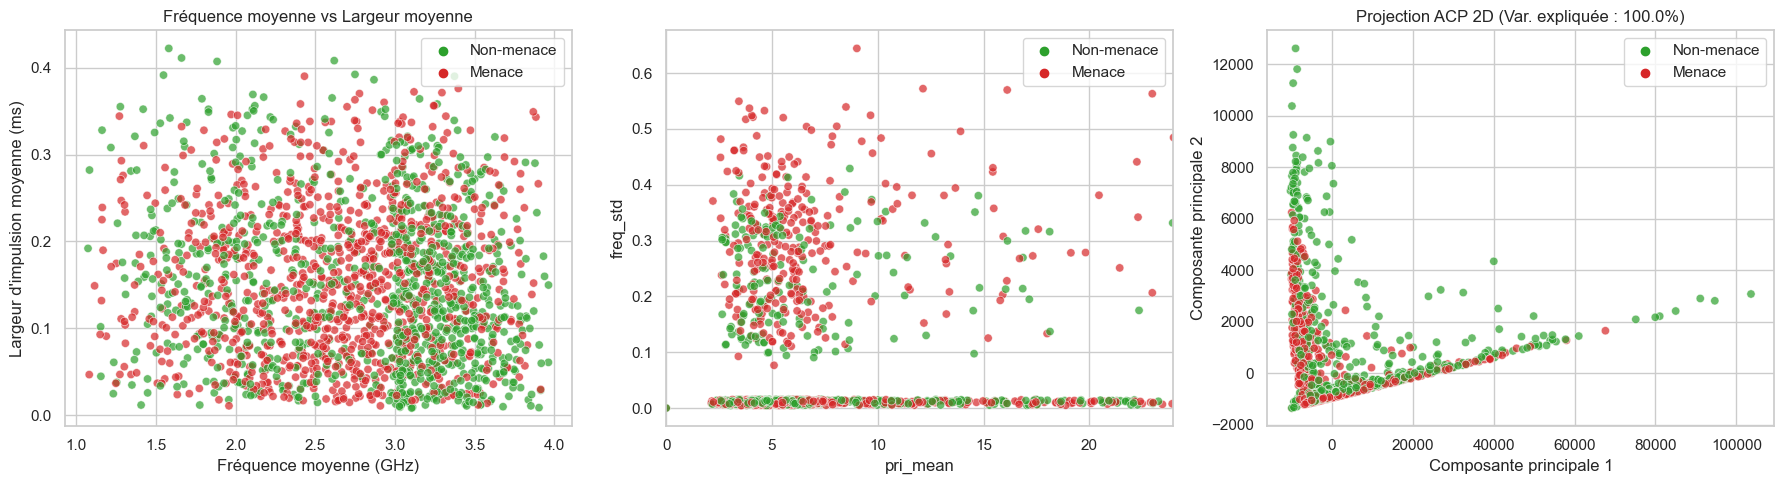

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Configuration du style graphique
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Palette de couleurs : vert pour non-menace (0), rouge pour menace (1)
colors = {0: '#2ca02c', 1: '#d62728'}
labels_map = {0: 'Non-menace', 1: 'Menace'}

# 1. Fréquence vs Largeur d'impulsion
sns.scatterplot(
    x=df_train['freq_mean'], 
    y=df_train['largeur_mean'], 
    hue=df_train['label'], 
    palette=colors, 
    alpha=0.7, 
    ax=axes[0]
)
axes[0].set_title("Fréquence moyenne vs Largeur moyenne")
axes[0].set_xlabel("Fréquence moyenne (GHz)")
axes[0].set_ylabel("Largeur d'impulsion moyenne (ms)")

# 2. PRI moyen vs Agilité spectrale (std_freq)
sns.scatterplot(
    x=df_train['pri_mean'], 
    y=df_train['freq_std'], 
    hue=df_train['label'], 
    palette=colors, 
    alpha=0.7, 
    ax=axes[1]
)
# Option B : Tronquer l'affichage au 95e percentile
max_pri = df_train['pri_mean'].quantile(0.95)
axes[1].set_xlim(0, max_pri)

# 3. Projection ACP 2D sur toutes les features
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1], 
    hue=y_train, 
    palette=colors, 
    alpha=0.7, 
    ax=axes[2]
)
axes[2].set_title(f"Projection ACP 2D (Var. expliquée : {pca.explained_variance_ratio_.sum():.1%})")
axes[2].set_xlabel("Composante principale 1")
axes[2].set_ylabel("Composante principale 2")

# Mise à jour des légendes
for ax in axes:
    handles, _ = ax.get_legend_handles_labels()
    ax.legend(handles=handles, labels=['Non-menace', 'Menace'])

plt.tight_layout()
plt.show()

In [55]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Entraînement de la baseline
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# 2. Évaluation sur validation
y_pred = clf.predict(X_valid)
print(f"Accuracy Valid : {accuracy_score(y_valid, y_pred):.4f}")
print("\nMatrice de confusion :")
print(confusion_matrix(y_valid, y_pred))

# 3. Affichage des 10 features les plus discriminantes
importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

print("\nTop 10 des features les plus importantes :")
for f in range(10):
    idx = indices[f]
    print(f"{f+1}. Feature {idx} ({feature_names[idx]}): {importances[idx]:.4f}")

Accuracy Valid : 0.8180

Matrice de confusion :
[[451  64]
 [118 367]]

Top 10 des features les plus importantes :
1. Feature 26 (pri_std): 0.0942
2. Feature 14 (puissance_median): 0.0559
3. Feature 25 (pri_mean): 0.0510
4. Feature 10 (puissance_mean): 0.0481
5. Feature 1 (freq_std): 0.0414
6. Feature 0 (freq_mean): 0.0379
7. Feature 11 (puissance_std): 0.0355
8. Feature 4 (freq_median): 0.0351
9. Feature 2 (freq_min): 0.0345
10. Feature 35 (n_impulsions): 0.0343


In [56]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# --- STEP 1 : Séparation des datasets selon le régime (threshold = 0.4 GHz) ---
mask_train_agile = df_train['freq_q90_10'] > 0.4
mask_train_mono = ~mask_train_agile

mask_valid_agile = df_valid['freq_q90_10'] > 0.4
mask_valid_mono = ~mask_valid_agile

print(
    f"Train - Mono: {mask_train_mono.sum()} | Agile: {mask_train_agile.sum()}"
)
print(
    f"Valid - Mono: {mask_valid_mono.sum()} | Agile: {mask_valid_agile.sum()}"
)

# Séparation X / y (sans la colonne 'label')
features_cols = [c for c in df_train.columns if c != 'label']

X_tr_mono, y_tr_mono = (
    df_train.loc[mask_train_mono, features_cols],
    df_train.loc[mask_train_mono, 'label'],
)
X_tr_agile, y_tr_agile = (
    df_train.loc[mask_train_agile, features_cols],
    df_train.loc[mask_train_agile, 'label'],
)

X_va_mono, y_va_mono = (
    df_valid.loc[mask_valid_mono, features_cols],
    df_valid.loc[mask_valid_mono, 'label'],
)
X_va_agile, y_va_agile = (
    df_valid.loc[mask_valid_agile, features_cols],
    df_valid.loc[mask_valid_agile, 'label'],
)

# --- STEP 2 : Entraînement des 2 modèles spécialistes ---
model_mono = HistGradientBoostingClassifier(random_state=42)
model_agile = HistGradientBoostingClassifier(random_state=42)

model_mono.fit(X_tr_mono, y_tr_mono)
model_agile.fit(X_tr_agile, y_tr_agile)

# --- STEP 3 : Prédiction par aiguillage ---
y_pred_mono = model_mono.predict(X_va_mono) if len(X_va_mono) > 0 else np.array([])
y_pred_agile = (
    model_agile.predict(X_va_agile) if len(X_va_agile) > 0 else np.array([])
)

# Réassemblage des prédictions dans l'ordre initial
y_pred_global = np.zeros(len(df_valid), dtype=int)
y_pred_global[mask_valid_mono] = y_pred_mono
y_pred_global[mask_valid_agile] = y_pred_agile

# --- STEP 4 : Évaluation globale ---
acc_global = accuracy_score(y_valid, y_pred_global)
cm = confusion_matrix(y_valid, y_pred_global)

print("\n" + "=" * 40)
print(f"Accuracy globale Option A : {acc_global:.4f}")
print("Matrice de confusion globale :")
print(cm)
print("=" * 40)

Train - Mono: 1568 | Agile: 432
Valid - Mono: 782 | Agile: 218


c:\Users\pchey\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\pchey\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\pchey\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\pchey\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\pchey\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(e


Accuracy globale Option A : 0.7990
Matrice de confusion globale :
[[428  87]
 [114 371]]


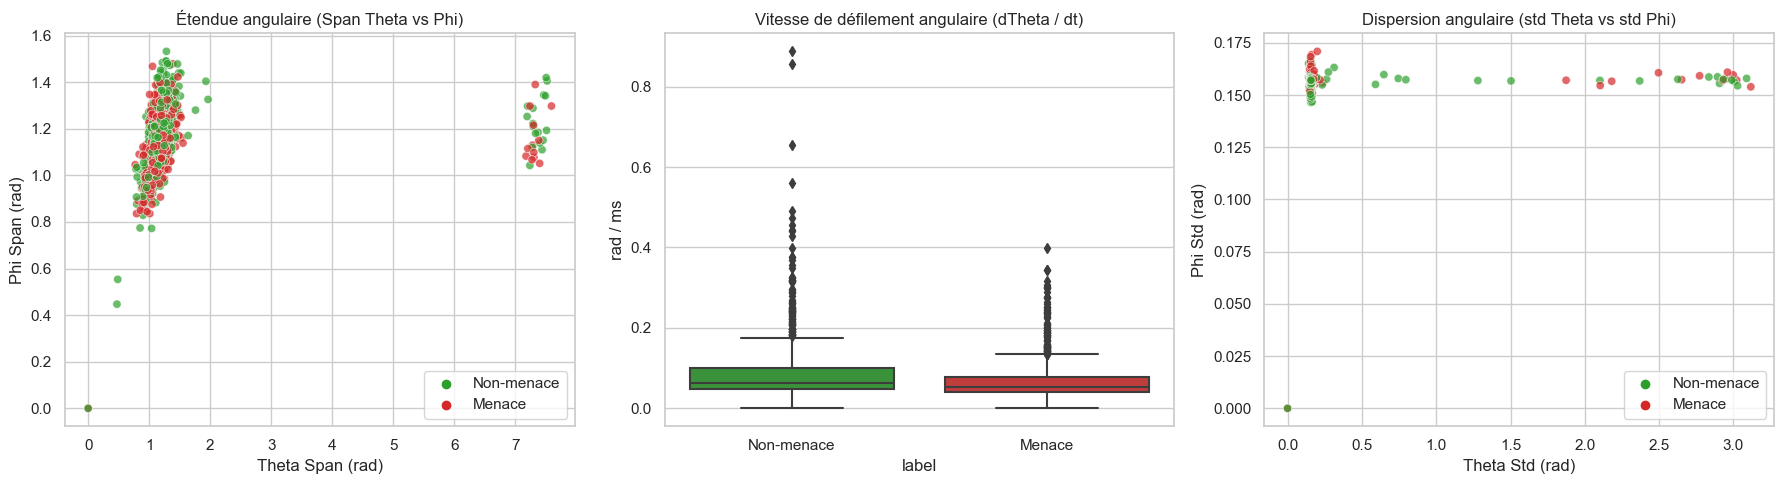

In [58]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

geo_features = []
labels = []

# Extraction sur le jeu de train
for fname, label in dict_labels.items():
  filepath = Path(f'./donnees/train/{fname}.npz')
  if not filepath.exists():
    continue

  pdw = np.load(filepath)
  dates = np.sort(np.asarray(pdw['date'], dtype=np.float64))
  theta = np.asarray(pdw['theta'], dtype=np.float64)
  phi = np.asarray(pdw['phi'], dtype=np.float64)

  if len(dates) > 1:
    dt = np.diff(dates)
    # Filtre sur deltas valides pour calculer la vitesse angulaire
    valid_mask = dt > 0.0
    d_theta = np.abs(np.diff(theta))
    d_phi = np.abs(np.diff(phi))

    speed_theta = (
        np.mean(d_theta[valid_mask] / dt[valid_mask])
        if np.any(valid_mask)
        else 0.0
    )
    speed_phi = (
        np.mean(d_phi[valid_mask] / dt[valid_mask])
        if np.any(valid_mask)
        else 0.0
    )
  else:
    speed_theta, speed_phi = 0.0, 0.0

  geo_features.append({
      'theta_span': np.ptp(theta),  # max - min
      'phi_span': np.ptp(phi),
      'theta_std': np.std(theta),
      'phi_std': np.std(phi),
      'speed_theta': speed_theta,  # d_theta / dt (rad/ms)
      'speed_phi': speed_phi,
      'label': 1 if label == 'menace' else 0,
  })

df_geo = pd.DataFrame(geo_features)

# Visualisation des distributions
colors = {0: '#2ca02c', 1: '#d62728'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Étendue theta vs Étendue phi
sns.scatterplot(
    data=df_geo,
    x='theta_span',
    y='phi_span',
    hue='label',
    palette=colors,
    alpha=0.7,
    ax=axes[0],
)
axes[0].set_title('Étendue angulaire (Span Theta vs Phi)')
axes[0].set_xlabel('Theta Span (rad)')
axes[0].set_ylabel('Phi Span (rad)')

# 2. Vitesse de défilement angulaire en Theta
sns.boxplot(
    data=df_geo, x='label', y='speed_theta', palette=colors, ax=axes[1]
)
axes[1].set_title('Vitesse de défilement angulaire (dTheta / dt)')
axes[1].set_xticklabels(['Non-menace', 'Menace'])
axes[1].set_ylabel('rad / ms')

# 3. Dispersion angulaire (std theta vs std phi)
sns.scatterplot(
    data=df_geo,
    x='theta_std',
    y='phi_std',
    hue='label',
    palette=colors,
    alpha=0.7,
    ax=axes[2],
)
axes[2].set_title('Dispersion angulaire (std Theta vs std Phi)')
axes[2].set_xlabel('Theta Std (rad)')
axes[2].set_ylabel('Phi Std (rad)')

for ax in [axes[0], axes[2]]:
  handles, _ = ax.get_legend_handles_labels()
  ax.legend(handles=handles, labels=['Non-menace', 'Menace'])

plt.tight_layout()
plt.show()

In [59]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Masques de séparation (seuil à 0.4 GHz)
mask_train_agile = df_train['freq_q90_10'] > 0.4
mask_train_mono = ~mask_train_agile

mask_valid_agile = df_valid['freq_q90_10'] > 0.4
mask_valid_mono = ~mask_valid_agile

# Extraction des matrices X et y
features_cols = [c for c in df_train.columns if c != 'label']

X_tr_mono, y_tr_mono = (
    df_train.loc[mask_train_mono, features_cols],
    df_train.loc[mask_train_mono, 'label'],
)
X_tr_agile, y_tr_agile = (
    df_train.loc[mask_train_agile, features_cols],
    df_train.loc[mask_train_agile, 'label'],
)

X_va_mono, y_va_mono = (
    df_valid.loc[mask_valid_mono, features_cols],
    df_valid.loc[mask_valid_mono, 'label'],
)
X_va_agile, y_va_agile = (
    df_valid.loc[mask_valid_agile, features_cols],
    df_valid.loc[mask_valid_agile, 'label'],
)

print(f'Train -> Mono: {len(X_tr_mono)} | Agile: {len(X_tr_agile)}')
print(f'Valid -> Mono: {len(X_va_mono)} | Agile: {len(X_va_agile)}')

# 2. Entraînement de deux Random Forest indépendants
rf_mono = RandomForestClassifier(n_estimators=100, random_state=42)
rf_agile = RandomForestClassifier(n_estimators=100, random_state=42)

rf_mono.fit(X_tr_mono, y_tr_mono)
rf_agile.fit(X_tr_agile, y_tr_agile)

# 3. Évaluation sur chaque spécialiste
y_pred_mono = rf_mono.predict(X_va_mono) if len(X_va_mono) > 0 else []
y_pred_agile = rf_agile.predict(X_va_agile) if len(X_va_agile) > 0 else []

acc_mono = accuracy_score(y_va_mono, y_pred_mono)
acc_agile = accuracy_score(y_va_agile, y_pred_agile)

print(f'\nAccuracy Spécialiste Mono : {acc_mono:.4f}')
print(f'Accuracy Spécialiste Agile : {acc_agile:.4f}')

# 4. Assemblage global pour évaluer la matrice de confusion globale
y_pred_global = np.zeros(len(df_valid), dtype=int)
y_pred_global[mask_valid_mono] = y_pred_mono
y_pred_global[mask_valid_agile] = y_pred_agile

acc_global = accuracy_score(y_valid, y_pred_global)
cm_global = confusion_matrix(y_valid, y_pred_global)

print('\n' + '=' * 40)
print(f'Accuracy Globale (Option A avec Random Forest) : {acc_global:.4f}')
print('Matrice de confusion globale :')
print(cm_global)
print('=' * 40)

Train -> Mono: 1568 | Agile: 432
Valid -> Mono: 782 | Agile: 218

Accuracy Spécialiste Mono : 0.7749
Accuracy Spécialiste Agile : 0.8853

Accuracy Globale (Option A avec Random Forest) : 0.7990
Matrice de confusion globale :
[[446  69]
 [132 353]]


In [60]:
import numpy as np

feature_cols = [c for c in df_train.columns if c != 'label']

def display_top_features(model, feature_names, title="", top_n=10):
    importances = model.feature_importances_
    indices = np.argsort(importances)[::-1]
    
    print(f"\n{'='*15} {title} {'='*15}")
    for f in range(top_n):
        idx = indices[f]
        print(f"{f+1:2d}. {feature_names[idx]:<22} : {importances[idx]:.4f}")

# Affichage pour le modèle Mono-fréquence
display_top_features(rf_mono, feature_cols, title="Spécialiste MONO (freq_q90_10 <= 0.4)")

# Affichage pour le modèle Agile
display_top_features(rf_agile, feature_cols, title="Spécialiste AGILE (freq_q90_10 > 0.4)")


=============== Spécialiste MONO (freq_q90_10 <= 0.4) ===============
 1. pri_std                : 0.1072
 2. puissance_median       : 0.0571
 3. puissance_mean         : 0.0552
 4. pri_mean               : 0.0516
 5. n_impulsions           : 0.0450
 6. puissance_std          : 0.0407
 7. puissance_max          : 0.0368
 8. phi_min                : 0.0362
 9. freq_max               : 0.0279
10. theta_std              : 0.0272

=============== Spécialiste AGILE (freq_q90_10 > 0.4) ===============
 1. freq_mean              : 0.1394
 2. freq_min               : 0.1203
 3. freq_max               : 0.0953
 4. freq_median            : 0.0730
 5. freq_entropy           : 0.0696
 6. freq_q90_10            : 0.0381
 7. puissance_median       : 0.0376
 8. freq_std               : 0.0355
 9. pri_mean               : 0.0348
10. puissance_mean         : 0.0322


In [61]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Features completes (sans la colonne label)
feature_cols = [c for c in df_train.columns if c != 'label']

X_tr = df_train[feature_cols]
y_tr = df_train['label']
X_va = df_valid[feature_cols]
y_va = df_valid['label']

# 1. Entraînement du Gradient Boosting
model_hgb = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.05, max_leaf_nodes=31, random_state=42
)
model_hgb.fit(X_tr, y_tr)

# 2. Obtention des probabilités sur Validation
y_proba_valid = model_hgb.predict_proba(X_va)[:, 1]

# 3. Prédiction avec seuil standard (0.5)
y_pred_default = (y_proba_valid >= 0.5).astype(int)

print(
    '=== HistGradientBoosting (Seuil 0.5) ==='
)
print(f'Accuracy : {accuracy_score(y_va, y_pred_default):.4f}')
print('Matrice de confusion :')
print(confusion_matrix(y_va, y_pred_default))

# 4. Optimisation du seuil pour la détection de menaces (priorité : réduire les faux négatifs)
# En guerre électronique, on préfère une fausse alerte plutôt que manquer une menace !
seuil_optimise = 0.35  # Décale le seuil pour capturer plus de menaces
y_pred_opt = (y_proba_valid >= seuil_optimise).astype(int)

print(
    f'\n=== HistGradientBoosting (Seuil optimisé {seuil_optimise}) ==='
)
print(f'Accuracy : {accuracy_score(y_va, y_pred_opt):.4f}')
print('Matrice de confusion :')
print(confusion_matrix(y_va, y_pred_opt))

=== HistGradientBoosting (Seuil 0.5) ===
Accuracy : 0.8140
Matrice de confusion :
[[431  84]
 [102 383]]

=== HistGradientBoosting (Seuil optimisé 0.35) ===
Accuracy : 0.7970
Matrice de confusion :
[[389 126]
 [ 77 408]]


In [67]:
from scipy.stats import mode


def extract_features_v3(pdw):
  dates = np.sort(np.asarray(pdw['date'], dtype=np.float64))
  frequences = np.asarray(pdw['frequence'], dtype=np.float64)
  largeurs = np.asarray(pdw['largeur'], dtype=np.float64)
  puissances = np.asarray(pdw['puissance'], dtype=np.float64)
  theta = np.asarray(pdw['theta'], dtype=np.float64)
  phi = np.asarray(pdw['phi'], dtype=np.float64)

  features = []

  # --- 1. TRAITEMENT DU PRI (Robuste au mitage) ---
  if len(dates) > 1:
    raw_pri = np.diff(dates)
    # Filtrage des deltas aberrants (> 100 ms = trou d'émission/balayage)
    valid_pri = raw_pri[(raw_pri > 0.0) & (raw_pri < 100.0)]

    if len(valid_pri) > 0:
      pri_q10, pri_q25, pri_q50, pri_q75 = np.percentile(
          valid_pri, [10, 25, 50, 75]
      )
      pri_std = np.std(valid_pri)
      # Estimation du mode du PRI (binning à 0.01 ms)
      counts, bin_edges = np.histogram(
          valid_pri, bins=np.arange(0, 100, 0.05)
      )
      pri_mode = bin_edges[np.argmax(counts)]
    else:
      pri_q10 = pri_q25 = pri_q50 = pri_q75 = pri_std = pri_mode = 0.0
  else:
    pri_q10 = pri_q25 = pri_q50 = pri_q75 = pri_std = pri_mode = 0.0

  features.extend(
      [pri_q10, pri_q25, pri_q50, pri_q75, pri_std, pri_mode]
  )

  # --- 2. TRAITEMENT DE LA FRÉQUENCE ---
  if len(frequences) > 0:
    f_mean, f_std = np.mean(frequences), np.std(frequences)
    f_q10, f_q50, f_q90 = np.percentile(frequences, [10, 50, 90])
    f_span = f_q90 - f_q10  # Étalement utile
  else:
    f_mean = f_std = f_q10 = f_q50 = f_q90 = f_span = 0.0

  features.extend([f_mean, f_std, f_q10, f_q50, f_q90, f_span])

  # --- 3. LARGEUR & PUISSANCE ---
  for var in [largeurs, puissances]:
    if len(var) > 0:
      features.extend(
          [np.mean(var), np.std(var), np.median(var), np.max(var)]
      )
    else:
      features.extend([0.0, 0.0, 0.0, 0.0])

  # --- 4. GÉOMÉTRIE (THETA / PHI) ---
  for var in [theta, phi]:
    if len(var) > 0:
      features.extend([np.mean(var), np.ptp(var), np.std(var)])
    else:
      features.extend([0.0, 0.0, 0.0])

  # --- 5. ACTIVITÉ & DENSITÉ ---
  n_imp = float(len(dates))
  duration = (dates[-1] - dates[0]) if len(dates) > 1 else 1.0
  density = n_imp / (duration + 1e-5)  # Impulsions par ms

  features.extend([n_imp, density])

  return np.array(features, dtype=np.float64)

def load_dataset(data_dir, labels_json_path):
    with open(labels_json_path, 'r') as f:
        labels_dict = json.load(f)
        
    X, y = [], []
    data_path = Path(data_dir)
    
    for fname, label in labels_dict.items():
        filepath = data_path / f"{fname}.npz"
        if not filepath.exists():
            continue
            
        pdw = np.load(filepath)
        feat = extract_features_v3(pdw)
        
        X.append(feat)
        y.append(1 if label == 'menace' else 0)
        
    return np.array(X), np.array(y)

X_train, y_train = load_dataset('./donnees/train', './donnees/train_labels.json')
X_valid, y_valid = load_dataset('./donnees/valid', './donnees/valid_labels.json')
X_test, y_test = load_dataset('./donnees/test', './donnees/test_labels.json')

print(f"Forme de X_train : {X_train.shape}")
print(f"Forme de y_train : {y_train.shape}")

Forme de X_train : (2000, 28)
Forme de y_train : (2000,)


In [69]:
import pandas as pd

# 1. Définition explicite des noms de colonnes dans l'ordre exact de extract_features_v3
feature_names = [
    # PRI (6)
    'pri_q10',
    'pri_q25',
    'pri_q50',
    'pri_q75',
    'pri_std',
    'pri_mode',
    # Fréquence (6)
    'freq_mean',
    'freq_std',
    'freq_q10',
    'freq_q50',
    'freq_q90',
    'freq_span',
    # Largeur (4)
    'largeur_mean',
    'largeur_std',
    'largeur_median',
    'largeur_max',
    # Puissance (4)
    'puissance_mean',
    'puissance_std',
    'puissance_median',
    'puissance_max',
    # Géométrie Theta (3)
    'theta_mean',
    'theta_span',
    'theta_std',
    # Géométrie Phi (3)
    'phi_mean',
    'phi_span',
    'phi_std',
    # Activité & Densité (2)
    'n_impulsions',
    'density',
]

# 2. Création des DataFrames pandas
df_train = pd.DataFrame(X_train, columns=feature_names)
df_train['label'] = y_train

df_valid = pd.DataFrame(X_valid, columns=feature_names)
df_valid['label'] = y_valid

df_test = pd.DataFrame(X_test, columns=feature_names)
df_test['label'] = y_test

df_test.head()

,pri_q10,pri_q25,pri_q50,pri_q75,pri_std,pri_mode,freq_mean,freq_std,freq_q10,freq_q50,...,puissance_max,theta_mean,theta_span,theta_std,phi_mean,phi_span,phi_std,n_impulsions,density,label
0,2.00000,2.0,4.0,8.00,6.020888,2.0,2.541905,0.009923,2.529297,2.541016,...,-58.75000,-2.448487,1.177734,0.158337,1.583434,1.110840,0.156355,7420.0,0.388239,1
1,0.75000,1.0,2.0,4.00,3.384075,2.0,1.565446,0.006246,1.557617,1.565430,...,-51.46875,-2.569958,1.315430,0.159843,1.593758,1.266113,0.154619,19931.0,1.099519,0
2,0.25000,0.5,0.5,0.75,2.387013,0.5,3.308363,0.013167,3.291016,3.308594,...,-91.00000,0.689964,1.038086,0.157615,1.594097,0.992188,0.161951,1529.0,0.096234,1
3,2.00000,2.0,4.0,8.00,6.276725,2.0,2.571413,0.010400,2.558594,2.572266,...,-65.06250,2.816599,1.068359,0.156107,1.582566,1.167969,0.158345,5607.0,0.377214,1
4,0.84375,1.0,1.0,2.00,3.852327,1.0,3.670406,0.014619,3.652344,3.669922,...,-74.12500,0.832233,1.190796,0.155395,1.578369,1.104492,0.158708,5550.0,0.409664,0


In [70]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Features completes (sans la colonne label)
feature_cols = [c for c in df_train.columns if c != 'label']

X_tr = df_train[feature_cols]
y_tr = df_train['label']
X_va = df_valid[feature_cols]
y_va = df_valid['label']

# 1. Entraînement du Gradient Boosting
model_hgb = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.05, max_leaf_nodes=31, random_state=42
)
model_hgb.fit(X_tr, y_tr)

# 2. Obtention des probabilités sur Validation
y_proba_valid = model_hgb.predict_proba(X_va)[:, 1]

# 3. Prédiction avec seuil standard (0.5)
y_pred_default = (y_proba_valid >= 0.5).astype(int)

print(
    '=== HistGradientBoosting (Seuil 0.5) ==='
)
print(f'Accuracy : {accuracy_score(y_va, y_pred_default):.4f}')
print('Matrice de confusion :')
print(confusion_matrix(y_va, y_pred_default))

# 4. Optimisation du seuil pour la détection de menaces (priorité : réduire les faux négatifs)
# En guerre électronique, on préfère une fausse alerte plutôt que manquer une menace !
seuil_optimise = 0.35  # Décale le seuil pour capturer plus de menaces
y_pred_opt = (y_proba_valid >= seuil_optimise).astype(int)

print(
    f'\n=== HistGradientBoosting (Seuil optimisé {seuil_optimise}) ==='
)
print(f'Accuracy : {accuracy_score(y_va, y_pred_opt):.4f}')
print('Matrice de confusion :')
print(confusion_matrix(y_va, y_pred_opt))

=== HistGradientBoosting (Seuil 0.5) ===
Accuracy : 0.8160
Matrice de confusion :
[[424  91]
 [ 93 392]]

=== HistGradientBoosting (Seuil optimisé 0.35) ===
Accuracy : 0.8030
Matrice de confusion :
[[386 129]
 [ 68 417]]


In [71]:
import json
from pathlib import Path
import numpy as np
import pandas as pd


def extract_features_v4(pdw):
  # 1. Tri synchrone de toutes les séries temporelles selon les dates
  raw_dates = np.asarray(pdw['date'], dtype=np.float64)
  order = np.argsort(raw_dates)

  dates = raw_dates[order]
  frequences = np.asarray(pdw['frequence'], dtype=np.float64)[order]
  largeurs = np.asarray(pdw['largeur'], dtype=np.float64)[order]
  puissances = np.asarray(pdw['puissance'], dtype=np.float64)[order]
  theta = np.asarray(pdw['theta'], dtype=np.float64)[order]
  phi = np.asarray(pdw['phi'], dtype=np.float64)[order]

  features = []

  # --- 1. PRI (Robustesse au mitage) ---
  if len(dates) > 1:
    raw_pri = np.diff(dates)
    valid_pri = raw_pri[(raw_pri > 0.0) & (raw_pri < 100.0)]
    if len(valid_pri) > 0:
      pri_q10, pri_q25, pri_q50, pri_q75 = np.percentile(
          valid_pri, [10, 25, 50, 75]
      )
      pri_std = np.std(valid_pri)
      counts, bin_edges = np.histogram(
          valid_pri, bins=np.arange(0, 100, 0.05)
      )
      pri_mode = bin_edges[np.argmax(counts)]
    else:
      pri_q10 = pri_q25 = pri_q50 = pri_q75 = pri_std = pri_mode = 0.0
  else:
    pri_q10 = pri_q25 = pri_q50 = pri_q75 = pri_std = pri_mode = 0.0

  features.extend(
      [pri_q10, pri_q25, pri_q50, pri_q75, pri_std, pri_mode]
  )

  # --- 2. FRÉQUENCE ---
  if len(frequences) > 0:
    f_mean, f_std = np.mean(frequences), np.std(frequences)
    f_q10, f_q50, f_q90 = np.percentile(frequences, [10, 50, 90])
    f_span = f_q90 - f_q10
  else:
    f_mean = f_std = f_q10 = f_q50 = f_q90 = f_span = 0.0

  features.extend([f_mean, f_std, f_q10, f_q50, f_q90, f_span])

  # --- 3. LARGEUR & PUISSANCE ---
  for var in [largeurs, puissances]:
    if len(var) > 0:
      features.extend(
          [np.mean(var), np.std(var), np.median(var), np.max(var)]
      )
    else:
      features.extend([0.0, 0.0, 0.0, 0.0])

  # --- 4. GÉOMÉTRIE & CINÉMATIQUE ANGULAIRE (dTheta/dt, dPhi/dt) ---
  if len(dates) > 1:
    dt = np.diff(dates)
    valid_mask = dt > 0.0

    if np.any(valid_mask):
      dt_v = dt[valid_mask]
      d_theta = np.abs(np.diff(theta))[valid_mask]
      d_phi = np.abs(np.diff(phi))[valid_mask]

      v_theta = d_theta / dt_v  # rad/ms
      v_phi = d_phi / dt_v  # rad/ms
      v_total = np.sqrt(v_theta**2 + v_phi**2)

      speed_theta_mean, speed_theta_max = np.mean(v_theta), np.max(v_theta)
      speed_phi_mean, speed_phi_max = np.mean(v_phi), np.max(v_phi)
      speed_total_mean = np.mean(v_total)
    else:
      speed_theta_mean = speed_theta_max = speed_phi_mean = speed_phi_max = (
          speed_total_mean
      ) = 0.0
  else:
    speed_theta_mean = speed_theta_max = speed_phi_mean = speed_phi_max = (
        speed_total_mean
    ) = 0.0

  theta_span = np.ptp(theta) if len(theta) > 0 else 0.0
  phi_span = np.ptp(phi) if len(phi) > 0 else 0.0
  theta_std = np.std(theta) if len(theta) > 0 else 0.0
  phi_std = np.std(phi) if len(phi) > 0 else 0.0

  features.extend([
      theta_span,
      phi_span,
      theta_std,
      phi_std,
      speed_theta_mean,
      speed_theta_max,
      speed_phi_mean,
      speed_phi_max,
      speed_total_mean,
  ])

  # --- 5. ACTIVITÉ & DENSITÉ ---
  n_imp = float(len(dates))
  duration = (dates[-1] - dates[0]) if len(dates) > 1 else 1.0
  density = n_imp / (duration + 1e-5)

  features.extend([n_imp, density])

  return np.array(features, dtype=np.float64)


def load_dataset_v4(data_dir, labels_json_path):
  with open(labels_json_path, 'r') as f:
    labels_dict = json.load(f)

  X, y = [], []
  data_path = Path(data_dir)

  for fname, label in labels_dict.items():
    filepath = data_path / f'{fname}.npz'
    if not filepath.exists():
      continue

    pdw = np.load(filepath)
    feat = extract_features_v4(pdw)

    X.append(feat)
    y.append(1 if label == 'menace' else 0)

  return np.array(X), np.array(y)

In [75]:
feature_names_v4 = [
    # PRI (6)
    'pri_q10',
    'pri_q25',
    'pri_q50',
    'pri_q75',
    'pri_std',
    'pri_mode',
    # Fréquence (6)
    'freq_mean',
    'freq_std',
    'freq_q10',
    'freq_q50',
    'freq_q90',
    'freq_span',
    # Largeur (4)
    'largeur_mean',
    'largeur_std',
    'largeur_median',
    'largeur_max',
    # Puissance (4)
    'puissance_mean',
    'puissance_std',
    'puissance_median',
    'puissance_max',
    # Cinématique Angulaire (9)
    'theta_span',
    'phi_span',
    'theta_std',
    'phi_std',
    'speed_theta_mean',
    'speed_theta_max',
    'speed_phi_mean',
    'speed_phi_max',
    'speed_total_mean',
    # Activité (2)
    'n_impulsions',
    'density',
]

# Chargement
X_train, y_train = load_dataset_v4(
    './donnees/train', './donnees/train_labels.json'
)
X_valid, y_valid = load_dataset_v4(
    './donnees/valid', './donnees/valid_labels.json'
)

df_train = pd.DataFrame(X_train, columns=feature_names_v4)
df_train['label'] = y_train

df_valid = pd.DataFrame(X_valid, columns=feature_names_v4)
df_valid['label'] = y_valid

In [77]:
print(f"Forme de X_train : {X_train.shape}")
print(f"Forme de y_train : {y_train.shape}")
df_train.head()

Forme de X_train : (2000, 31)
Forme de y_train : (2000,)


,pri_q10,pri_q25,pri_q50,pri_q75,pri_std,pri_mode,freq_mean,freq_std,freq_q10,freq_q50,...,theta_std,phi_std,speed_theta_mean,speed_theta_max,speed_phi_mean,speed_phi_max,speed_total_mean,n_impulsions,density,label
0,2.00,2.0000,4.0,8.0,6.249437,2.0,2.888942,0.011461,2.875000,2.888672,...,0.155693,0.158646,0.055774,0.547363,0.058550,0.673828,0.089927,7956.0,0.418589,0
1,2.00,2.7500,4.0,8.0,4.272824,4.0,3.608729,0.014385,3.589844,3.607422,...,0.156203,0.160193,0.045843,0.361572,0.049745,0.395508,0.074950,4281.0,0.297977,1
2,2.00,2.4375,4.0,8.0,3.650387,4.0,2.010611,0.008133,2.000000,2.009766,...,0.156721,0.155866,0.049209,0.318359,0.049092,0.328125,0.077523,4636.0,0.329103,0
3,1.00,2.0000,3.5,4.0,3.983007,4.0,3.231064,0.012996,3.214844,3.230469,...,0.157393,0.157750,0.077656,0.805664,0.077237,0.734375,0.121605,9749.0,0.616757,1
4,0.75,1.0000,2.0,4.0,4.071370,2.0,1.697499,0.006786,1.688477,1.697266,...,0.157487,0.157184,0.115352,1.459961,0.119218,1.324219,0.184181,19328.0,1.080546,0


In [78]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Features completes (sans la colonne label)
feature_cols = [c for c in df_train.columns if c != 'label']

X_tr = df_train[feature_cols]
y_tr = df_train['label']
X_va = df_valid[feature_cols]
y_va = df_valid['label']

# 1. Entraînement du Gradient Boosting
model_hgb = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.05, max_leaf_nodes=31, random_state=42
)
model_hgb.fit(X_tr, y_tr)

# 2. Obtention des probabilités sur Validation
y_proba_valid = model_hgb.predict_proba(X_va)[:, 1]

# 3. Prédiction avec seuil standard (0.5)
y_pred_default = (y_proba_valid >= 0.5).astype(int)

print(
    '=== HistGradientBoosting (Seuil 0.5) ==='
)
print(f'Accuracy : {accuracy_score(y_va, y_pred_default):.4f}')
print('Matrice de confusion :')
print(confusion_matrix(y_va, y_pred_default))

# 4. Optimisation du seuil pour la détection de menaces (priorité : réduire les faux négatifs)
# En guerre électronique, on préfère une fausse alerte plutôt que manquer une menace !
seuil_optimise = 0.35  # Décale le seuil pour capturer plus de menaces
y_pred_opt = (y_proba_valid >= seuil_optimise).astype(int)

print(
    f'\n=== HistGradientBoosting (Seuil optimisé {seuil_optimise}) ==='
)
print(f'Accuracy : {accuracy_score(y_va, y_pred_opt):.4f}')
print('Matrice de confusion :')
print(confusion_matrix(y_va, y_pred_opt))

=== HistGradientBoosting (Seuil 0.5) ===
Accuracy : 0.8140
Matrice de confusion :
[[423  92]
 [ 94 391]]

=== HistGradientBoosting (Seuil optimisé 0.35) ===
Accuracy : 0.8020
Matrice de confusion :
[[388 127]
 [ 71 414]]


In [79]:
import json
from pathlib import Path
import numpy as np
import pandas as pd


def extract_features_v5(pdw):
  raw_dates = np.asarray(pdw['date'], dtype=np.float64)  # ms
  order = np.argsort(raw_dates)

  dates = raw_dates[order]
  frequences = np.asarray(pdw['frequence'], dtype=np.float64)[order]
  largeurs = np.asarray(pdw['largeur'], dtype=np.float64)[order]
  puissances = np.asarray(pdw['puissance'], dtype=np.float64)[order]
  theta = np.asarray(pdw['theta'], dtype=np.float64)[order]
  phi = np.asarray(pdw['phi'], dtype=np.float64)[order]

  features = []

  # --- 1. RÉTRO-PROJECTION GÉOMÉTRIQUE AU SOL & CPA ---
  # Altitude = 10 km | Vitesse = 1000 km/h = 1000/3600000 km/ms
  v_avion = 1000.0 / 3600.0 / 1000.0  # km/ms
  z_avion = 10.0  # km

  if len(dates) > 0:
    # Distance projetée au sol depuis l'avion
    d_sol = z_avion * np.abs(np.tan(phi))

    # Position estimée du radar au sol pour chaque impulsion
    x_radar = d_sol * np.sin(theta)
    y_radar = (v_avion * dates) + (d_sol * np.cos(theta))

    # Coordonnées estimées de l'émetteur (médiane)
    x0 = float(np.median(x_radar))
    y0 = float(np.median(y_radar))

    # Distance minimale de survol (CPA - Closest Point of Approach)
    cpa_distance = float(np.sqrt(x0**2 + z_avion**2))

    # Dispersion spatiale (cohérence du ciblage au sol)
    pos_std = float(np.sqrt(np.std(x_radar) ** 2 + np.std(y_radar) ** 2))
  else:
    x0, y0, cpa_distance, pos_std = 0.0, 0.0, 0.0, 0.0

  features.extend([x0, y0, cpa_distance, pos_std])

  # --- 2. PRI (Robuste au mitage) ---
  if len(dates) > 1:
    raw_pri = np.diff(dates)
    valid_pri = raw_pri[(raw_pri > 0.0) & (raw_pri < 100.0)]
    if len(valid_pri) > 0:
      pri_q10, pri_q25, pri_q50, pri_q75 = np.percentile(
          valid_pri, [10, 25, 50, 75]
      )
      pri_std = float(np.std(valid_pri))
      counts, bin_edges = np.histogram(
          valid_pri, bins=np.arange(0, 100, 0.05)
      )
      pri_mode = float(bin_edges[np.argmax(counts)])
    else:
      pri_q10 = pri_q25 = pri_q50 = pri_q75 = pri_std = pri_mode = 0.0
  else:
    pri_q10 = pri_q25 = pri_q50 = pri_q75 = pri_std = pri_mode = 0.0

  features.extend(
      [pri_q10, pri_q25, pri_q50, pri_q75, pri_std, pri_mode]
  )

  # --- 3. FRÉQUENCE ---
  if len(frequences) > 0:
    f_mean, f_std = float(np.mean(frequences)), float(np.std(frequences))
    f_q10, f_q50, f_q90 = np.percentile(frequences, [10, 50, 90])
    f_span = float(f_q90 - f_q10)
  else:
    f_mean = f_std = f_q10 = f_q50 = f_q90 = f_span = 0.0

  features.extend([f_mean, f_std, f_q10, f_q50, f_q90, f_span])

  # --- 4. LARGEUR & PUISSANCE ---
  for var in [largeurs, puissances]:
    if len(var) > 0:
      features.extend([
          float(np.mean(var)),
          float(np.std(var)),
          float(np.median(var)),
          float(np.max(var)),
      ])
    else:
      features.extend([0.0, 0.0, 0.0, 0.0])

  # --- 5. ACTIVITÉ ---
  n_imp = float(len(dates))
  duration = float(dates[-1] - dates[0]) if len(dates) > 1 else 1.0
  density = n_imp / (duration + 1e-5)

  features.extend([n_imp, density])

  return np.array(features, dtype=np.float64)


def load_dataset_v5(data_dir, labels_json_path):
  with open(labels_json_path, 'r') as f:
    labels_dict = json.load(f)

  X, y = [], []
  data_path = Path(data_dir)

  for fname, label in labels_dict.items():
    filepath = data_path / f'{fname}.npz'
    if not filepath.exists():
      continue

    pdw = np.load(filepath)
    feat = extract_features_v5(pdw)

    X.append(feat)
    y.append(1 if label == 'menace' else 0)

  return np.array(X), np.array(y)

In [80]:
feature_names_v5 = [
    # Géométrie & CPA au sol (4)
    'x0_radar',
    'y0_radar',
    'cpa_distance',
    'pos_std',
    # PRI (6)
    'pri_q10',
    'pri_q25',
    'pri_q50',
    'pri_q75',
    'pri_std',
    'pri_mode',
    # Fréquence (6)
    'freq_mean',
    'freq_std',
    'freq_q10',
    'freq_q50',
    'freq_q90',
    'freq_span',
    # Largeur (4)
    'largeur_mean',
    'largeur_std',
    'largeur_median',
    'largeur_max',
    # Puissance (4)
    'puissance_mean',
    'puissance_std',
    'puissance_median',
    'puissance_max',
    # Activité (2)
    'n_impulsions',
    'density',
]

X_train, y_train = load_dataset_v5(
    './donnees/train', './donnees/train_labels.json'
)
X_valid, y_valid = load_dataset_v5(
    './donnees/valid', './donnees/valid_labels.json'
)

df_train = pd.DataFrame(X_train, columns=feature_names_v5)
df_train['label'] = y_train

df_valid = pd.DataFrame(X_valid, columns=feature_names_v5)
df_valid['label'] = y_valid

In [82]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, confusion_matrix

feature_cols = [c for c in df_train.columns if c != 'label']

# 1. Entraînement
model_hgb = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.03, max_leaf_nodes=31, random_state=42
)
model_hgb.fit(df_train[feature_cols], df_train['label'])

# 2. Évaluation à seuil 0.5
y_pred = model_hgb.predict(df_valid[feature_cols])

print('=== HistGradientBoosting V5 (Rétro-projection) ===')
print(f'Accuracy Valid : {accuracy_score(df_valid["label"], y_pred):.4f}')
print('Matrice de confusion :')
print(confusion_matrix(df_valid['label'], y_pred))

# 3. Calcul propre de la Permutation Importance
result = permutation_importance(
    model_hgb,
    df_valid[feature_cols],
    df_valid['label'],
    n_repeats=10,
    random_state=42,
)

importances_mean = result.importances_mean
indices = np.argsort(importances_mean)[::-1]

print('\nTop 10 des features les plus importantes :')
for f in range(10):
  idx = indices[f]
  print(
      f'{f+1:2d}. {feature_names_v5[idx]:<20} :'
      f' {importances_mean[idx]:.4f}'
  )

=== HistGradientBoosting V5 (Rétro-projection) ===
Accuracy Valid : 0.8200
Matrice de confusion :
[[427  88]
 [ 92 393]]

Top 10 des features les plus importantes :
 1. freq_mean            : 0.0955
 2. freq_std             : 0.0715
 3. pri_std              : 0.0570
 4. puissance_mean       : 0.0518
 5. puissance_max        : 0.0434
 6. density              : 0.0400
 7. freq_span            : 0.0293
 8. puissance_median     : 0.0277
 9. n_impulsions         : 0.0207
10. largeur_mean         : 0.0190


In [83]:
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Sélection des caractéristiques réellement discriminantes (nettoyage du bruit)
useful_cols = [
    c
    for c in df_train.columns
    if c not in ['x0_radar', 'y0_radar', 'cpa_distance', 'pos_std', 'label']
]

X_tr = df_train[useful_cols]
y_tr = df_train['label']
X_va = df_valid[useful_cols]
y_va = df_valid['label']

# 2. Définition des modèles de base (Apprenants de niveau 0)
estimators = [
    (
        'rf',
        RandomForestClassifier(
            n_estimators=250, max_depth=15, random_state=42, n_jobs=-1
        ),
    ),
    (
        'et',
        ExtraTreesClassifier(
            n_estimators=250, max_depth=15, random_state=42, n_jobs=-1
        ),
    ),
    (
        'hgb',
        HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.03, max_leaf_nodes=31, random_state=42
        ),
    ),
]

# 3. Méta-modèle de Stacking (Combinaison des prédictions)
stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    cv=5,
    n_jobs=-1,
)

# 4. Entraînement et Évaluation
stack_model.fit(X_tr, y_tr)
y_pred_stack = stack_model.predict(X_va)

print('=== Stacking Classifier (RF + ExtraTrees + HistGB) ===')
print(f'Accuracy Validation : {accuracy_score(y_va, y_pred_stack):.4f}')
print('\nMatrice de confusion :')
print(confusion_matrix(y_va, y_pred_stack))

=== Stacking Classifier (RF + ExtraTrees + HistGB) ===
Accuracy Validation : 0.8260

Matrice de confusion :
[[433  82]
 [ 92 393]]


In [84]:
# Évaluation finale sur le jeu de TEST
X_te = df_test[useful_cols]
y_te = df_test['label']

y_pred_test = stack_model.predict(X_te)

print("=== PERFORMANCES FINALES SUR LE JEU TEST ===")
print(f"Accuracy Test : {accuracy_score(y_te, y_pred_test):.4f}")
print("\nMatrice de confusion Test :")
print(confusion_matrix(y_te, y_pred_test))
print("\nRapport de classification Test :")
print(classification_report(y_te, y_pred_test, target_names=['Non-menace', 'Menace']))

=== PERFORMANCES FINALES SUR LE JEU TEST ===
Accuracy Test : 0.8330

Matrice de confusion Test :
[[411  71]
 [ 96 422]]

Rapport de classification Test :
              precision    recall  f1-score   support

  Non-menace       0.81      0.85      0.83       482
      Menace       0.86      0.81      0.83       518

    accuracy                           0.83      1000
   macro avg       0.83      0.83      0.83      1000
weighted avg       0.83      0.83      0.83      1000

